# Hearthstone Final Project
## BUAN/ITSS 4382 — Applied AI/ML | University of Texas at Dallas

### Predicting and Reducing Product Returns at Hearthstone Using Machine Learning

**Company:** Hearthstone — Online Furniture & Home Décor Marketplace  
**Dataset:** R-HEARTHSTONE.csv (10,000 orders, 20 columns)  
**Target Variable:** `customer_return` (Yes = 1, No = 0)  
**Course:** BUAN/ITSS 4382 — Applied AI/ML  
**Due Date:** November 17, 2026

---

### Business Context

Hearthstone is an online furniture and home décor marketplace competing with Wayfair, Overstock,
Article, and West Elm. Like many e-commerce furniture retailers, Hearthstone faces a critical
operational challenge: **product returns are expensive**. Each return involves reverse logistics,
warehouse restocking, potential product damage, and customer dissatisfaction.

This project investigates:
1. What percentage of orders are returned?
2. Which factors are most strongly associated with returns?
3. Can machine learning predict which orders are at high risk of return?
4. What operational actions should Hearthstone prioritize?

---

### Notebook Structure
1. Data Import  
2. Data Inspection & Understanding  
3. Data Cleaning & Preparation  
4. Exploratory Data Analysis (8 analyses)  
5. Feature Engineering & Selection  
6. Model Building (4 models)  
7. Model Evaluation  
8. Feature Importance & Interpretation  
9. Business Conclusions  
10. Recommendations  
11. Limitations & Ethical Considerations


---
## Section 1 — Data Import

We load the dataset and configure our Python environment.


In [1]:
import warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
from sklearn.model_selection import train_test_split, cross_val_score, StratifiedKFold
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.dummy import DummyClassifier
from sklearn.preprocessing import LabelEncoder, StandardScaler, OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    confusion_matrix, classification_report, roc_auc_score, roc_curve
)
warnings.filterwarnings('ignore')

# Plotting style
plt.rcParams.update({
    'figure.facecolor': 'white',
    'axes.facecolor':   '#f8f8f8',
    'axes.grid':        True,
    'grid.alpha':       0.4,
    'font.size':        11,
    'axes.titlesize':   13,
})
PALETTE = ['#2196F3', '#FF5722']
sns.set_palette(PALETTE)

import os
os.makedirs('charts', exist_ok=True)

# Load dataset
df = pd.read_csv('R-HEARTHSTONE.csv')
print(f"Dataset loaded successfully: {df.shape[0]:,} rows × {df.shape[1]} columns")
print(f"Columns: {df.columns.tolist()}")


Dataset loaded successfully: 10,000 rows × 20 columns
Columns: ['order_id', 'order_date', 'product_category', 'product_subcategory', 'product_price_usd', 'product_weight_lbs', 'product_dimensions_cuft', 'supplier_location', 'warehouse_location', 'customer_state', 'shipping_method', 'fulfillment_lead_time_days', 'assembly_required', 'product_damaged', 'customer_return', 'return_reason', 'customer_rating', 'order_value_usd', 'shipping_cost_usd', 'restocking_fee_usd']


---
## Section 2 — Data Inspection & Understanding

Before any analysis, we thoroughly examine the dataset to understand its structure,
detect data quality issues, and confirm the expected schema.


In [2]:
# Verify expected dimensions
expected_rows, expected_cols = 10000, 20
print(f"Expected: {expected_rows} rows × {expected_cols} cols")
print(f"Actual  : {df.shape[0]} rows × {df.shape[1]} cols")
assert df.shape == (expected_rows, expected_cols), "Dimension mismatch!"
print("✓ Dimensions verified")


Expected: 10000 rows × 20 cols
Actual  : 10000 rows × 20 cols
✓ Dimensions verified


In [3]:
# Data types
print("Column Data Types:")
print(df.dtypes)


Column Data Types:
order_id                          str
order_date                        str
product_category                  str
product_subcategory               str
product_price_usd             float64
product_weight_lbs            float64
product_dimensions_cuft       float64
supplier_location                 str
warehouse_location                str
customer_state                    str
shipping_method                   str
fulfillment_lead_time_days      int64
assembly_required                 str
product_damaged                   str
customer_return                   str
return_reason                     str
customer_rating                 int64
order_value_usd               float64
shipping_cost_usd             float64
restocking_fee_usd            float64
dtype: object


In [4]:
# First and last 5 rows
print("First 5 rows:")
df.head()


First 5 rows:


,order_id,order_date,product_category,product_subcategory,product_price_usd,product_weight_lbs,product_dimensions_cuft,supplier_location,warehouse_location,customer_state,shipping_method,fulfillment_lead_time_days,assembly_required,product_damaged,customer_return,return_reason,customer_rating,order_value_usd,shipping_cost_usd,restocking_fee_usd
0,WF000001,2024-04-12,Furniture,Beds,1263.85,116.11,71.20,China,IL,NY,Freight,29,Yes,No,Yes,Assembly Issues,2,1263.85,425.78,126.97
1,WF000002,2024-12-14,Home Decor,Vases,141.69,9.09,4.23,Vietnam,GA,VA,Expedited,13,No,No,Yes,Not As Described,2,141.69,40.97,28.86
2,WF000003,2024-09-27,Lighting,Table Lamps,364.45,21.93,15.49,Vietnam,NJ,FL,Expedited,16,No,No,No,NaN,4,364.45,73.37,0.00
3,WF000004,2024-04-16,Rugs,Outdoor Rugs,594.71,41.54,14.72,USA-East,NJ,CA,Freight,13,No,No,No,NaN,5,594.71,289.78,0.00
4,WF000005,2024-03-12,Bedding,Comforters,314.31,6.47,4.72,Mexico,OH,PA,Expedited,7,No,No,No,NaN,5,314.31,31.69,0.00


In [5]:
print("Last 5 rows:")
df.tail()


Last 5 rows:


,order_id,order_date,product_category,product_subcategory,product_price_usd,product_weight_lbs,product_dimensions_cuft,supplier_location,warehouse_location,customer_state,shipping_method,fulfillment_lead_time_days,assembly_required,product_damaged,customer_return,return_reason,customer_rating,order_value_usd,shipping_cost_usd,restocking_fee_usd
9995,WF009996,2024-05-27,Home Decor,Wall Art,278.75,10.97,8.33,Vietnam,GA,FL,Freight,22,No,No,No,NaN,3,278.75,231.98,0.00
9996,WF009997,2024-12-30,Furniture,Sofas,825.81,142.81,51.72,Vietnam,CA,IL,White Glove,39,Yes,No,Yes,Not As Described,2,825.81,584.13,175.15
9997,WF009998,2024-12-29,Kitchen,Cookware,213.63,8.31,5.64,China,TX,IL,Standard Ground,16,No,No,No,NaN,5,213.63,16.08,0.00
9998,WF009999,2024-05-19,Home Decor,Wall Art,175.37,6.80,2.88,USA-West,GA,AZ,Standard Ground,8,No,No,No,NaN,5,175.37,15.03,0.00
9999,WF010000,2024-07-08,Kitchen,Storage,212.25,22.83,10.52,China,IL,MA,Expedited,10,No,No,No,NaN,4,212.25,66.49,0.00


In [6]:
# Missing values
missing = df.isnull().sum()
missing_pct = (missing / len(df) * 100).round(2)
missing_df = pd.DataFrame({'Missing Count': missing, 'Missing %': missing_pct})
missing_df = missing_df[missing_df['Missing Count'] > 0]
print("Columns with missing values:")
print(missing_df)
print(f"\nNote: return_reason has {missing['return_reason']:,} NaN values ({missing_pct['return_reason']:.1f}%)")
print("This is EXPECTED — non-returned orders have no reason.")


Columns with missing values:
               Missing Count  Missing %
return_reason           6334      63.34

Note: return_reason has 6,334 NaN values (63.3%)
This is EXPECTED — non-returned orders have no reason.


In [7]:
# Duplicates
dup_rows = df.duplicated().sum()
dup_orders = df['order_id'].duplicated().sum()
print(f"Duplicate rows      : {dup_rows}")
print(f"Duplicate order IDs : {dup_orders}")
print("✓ No duplicates found — dataset is clean")


Duplicate rows      : 0
Duplicate order IDs : 0
✓ No duplicates found — dataset is clean


In [8]:
# Numerical summary statistics
print("Numerical Summary Statistics:")
df.describe().round(2)


Numerical Summary Statistics:


,product_price_usd,product_weight_lbs,product_dimensions_cuft,fulfillment_lead_time_days,customer_rating,order_value_usd,shipping_cost_usd,restocking_fee_usd
count,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00,10000.00
mean,692.98,46.88,25.71,20.55,3.30,692.98,132.87,59.17
std,679.47,41.76,24.39,9.47,1.45,679.47,155.74,116.10
min,20.13,2.01,0.63,4.00,1.00,20.13,11.17,0.00
25%,202.58,13.31,6.88,13.00,2.00,202.58,24.97,0.00
50%,373.13,29.78,15.64,20.00,4.00,373.13,53.92,0.00
75%,1051.09,75.46,38.97,27.00,5.00,1051.09,202.95,54.72
max,2499.75,149.95,118.54,53.00,5.00,2499.75,732.81,616.26


In [9]:
# Categorical value distributions
cat_cols = ['product_category','shipping_method','assembly_required','product_damaged','customer_return']
for col in cat_cols:
    print(f"\n--- {col} ---")
    print(df[col].value_counts(dropna=False))



--- product_category ---
product_category
Furniture     3515
Home Decor    1527
Rugs          1181
Lighting      1024
Bedding        949
Kitchen        824
Outdoor        616
Storage        364
Name: count, dtype: int64

--- shipping_method ---
shipping_method
Standard Ground    5761
Expedited          1831
White Glove        1538
Freight             870
Name: count, dtype: int64

--- assembly_required ---
assembly_required
No     6801
Yes    3199
Name: count, dtype: int64

--- product_damaged ---
product_damaged
No     8730
Yes    1270
Name: count, dtype: int64

--- customer_return ---
customer_return
No     6334
Yes    3666
Name: count, dtype: int64


In [10]:
# Date coverage
df_temp = df.copy()
df_temp['order_date_dt'] = pd.to_datetime(df_temp['order_date'])
print(f"Date range: {df_temp['order_date_dt'].min().date()} to {df_temp['order_date_dt'].max().date()}")
print(f"Unique months: {df_temp['order_date_dt'].dt.to_period('M').nunique()}")


Date range: 2024-01-01 to 2024-12-30
Unique months: 12


In [11]:
# Target distribution
target_counts = df['customer_return'].value_counts()
print("Target Variable Distribution (customer_return):")
print(target_counts)
print(f"\nReturn Rate: {target_counts['Yes'] / len(df):.2%}")


Target Variable Distribution (customer_return):
customer_return
No     6334
Yes    3666
Name: count, dtype: int64

Return Rate: 36.66%


---
## Section 3 — Data Cleaning & Preparation

### Key decisions:
- Convert Yes/No binary columns to 0/1
- Parse order_date as datetime
- Investigate return_reason NaN (intentional — not leaked)
- **Leakage prevention**: Exclude `return_reason`, `restocking_fee_usd`, `customer_rating`
- Stratified 80/20 train-test split with `random_state=42`


In [12]:
# Parse dates
df['order_date'] = pd.to_datetime(df['order_date'])

# Binary encode Yes/No columns
for col in ['assembly_required', 'product_damaged', 'customer_return']:
    df[col + '_bin'] = (df[col].str.strip() == 'Yes').astype(int)

# Target
df['target'] = df['customer_return_bin']

# Date features
df['order_month'] = df['order_date'].dt.month
df['order_quarter'] = df['order_date'].dt.quarter

# Verify return_reason NaN is intentional (only non-returned orders)
print("Return Reason × Customer Return Cross-tabulation:")
print(pd.crosstab(df['customer_return'], df['return_reason'].isna(),
                  rownames=['customer_return'], colnames=['return_reason is NaN']))
print("\n✓ Confirmed: NaN in return_reason only appears for non-returned orders")
print("  → We will NOT use return_reason as a predictive feature (target leakage)")


Return Reason × Customer Return Cross-tabulation:
return_reason is NaN  False  True 
customer_return                   
No                        0   6334
Yes                    3666      0

✓ Confirmed: NaN in return_reason only appears for non-returned orders
  → We will NOT use return_reason as a predictive feature (target leakage)


In [13]:
# Feature selection — avoiding data leakage
# EXCLUDED: return_reason (reveals target), restocking_fee_usd (post-return),
#           customer_rating (possibly post-experience)
# product_damaged_bin: included as post-delivery risk signal (noted in limitations)

FEATURES = [
    'product_price_usd', 'product_weight_lbs', 'product_dimensions_cuft',
    'fulfillment_lead_time_days', 'assembly_required_bin', 'product_damaged_bin',
    'order_month', 'order_quarter',
    'product_category', 'product_subcategory', 'supplier_location',
    'warehouse_location', 'customer_state', 'shipping_method',
]
TARGET = 'target'

X = df[FEATURES].copy()
y = df[TARGET].copy()

# Identify numeric vs categorical columns
num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

print(f"Features selected  : {len(FEATURES)}")
print(f"Numerical features : {num_cols}")
print(f"Categorical features: {cat_cols}")
print(f"\nTarget distribution:\n{y.value_counts()}")


Features selected  : 14
Numerical features : ['product_price_usd', 'product_weight_lbs', 'product_dimensions_cuft', 'fulfillment_lead_time_days', 'assembly_required_bin', 'product_damaged_bin']
Categorical features: ['product_category', 'product_subcategory', 'supplier_location', 'warehouse_location', 'customer_state', 'shipping_method']

Target distribution:
target
0    6334
1    3666
Name: count, dtype: int64


In [14]:
# 80/20 stratified train-test split
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print(f"Training set : {X_train.shape[0]:,} rows")
print(f"Test set     : {X_test.shape[0]:,} rows")
print(f"\nTraining return rate : {y_train.mean():.2%}")
print(f"Test return rate     : {y_test.mean():.2%}")
print("✓ Stratified split — class balance preserved in both sets")


Training set : 8,000 rows
Test set     : 2,000 rows

Training return rate : 36.66%
Test return rate     : 36.65%
✓ Stratified split — class balance preserved in both sets


---
## Section 4 — Exploratory Data Analysis

We conduct 8 targeted analyses to investigate factors associated with product returns.
Each analysis follows the structure:
1. Business question  
2. Code  
3. Visualization  
4. Findings  
5. Business relevance


### Analysis A — Overall Return Rate
**Business question:** What percentage of Hearthstone orders are returned?


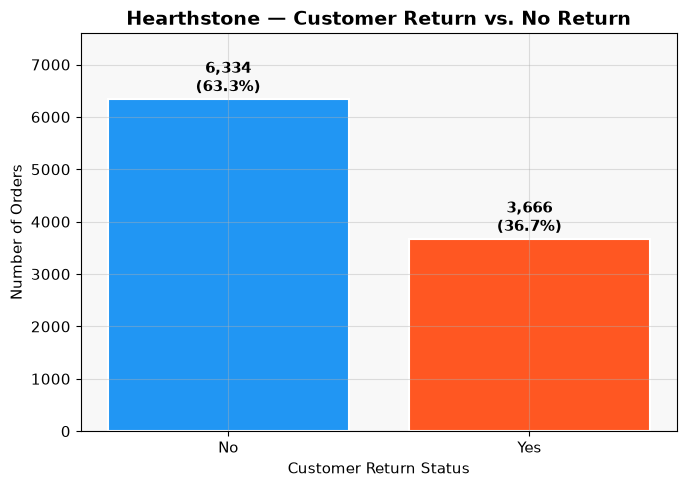

Overall return rate: 36.66%
Total returns      : 3,666 out of 10,000 orders

Finding: 36.7% of orders are returned — significantly higher than industry average (~20-25%)
Business relevance: This high rate is a major operational and financial risk for Hearthstone


In [15]:
fig, ax = plt.subplots(figsize=(7, 5))
counts = df['customer_return'].value_counts()
bars = ax.bar(counts.index, counts.values, color=['#2196F3','#FF5722'], edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, counts.values):
    pct = val / len(df) * 100
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 60,
            f'{val:,}\n({pct:.1f}%)', ha='center', va='bottom', fontweight='bold')
ax.set_title('Hearthstone — Customer Return vs. No Return', fontsize=14, fontweight='bold')
ax.set_xlabel('Customer Return Status')
ax.set_ylabel('Number of Orders')
ax.set_ylim(0, counts.max() * 1.2)
plt.tight_layout()
plt.savefig('charts/A_return_rate.png', dpi=150, bbox_inches='tight')
plt.show()

RETURN_RATE = df['target'].mean()
print(f"Overall return rate: {RETURN_RATE:.2%}")
print(f"Total returns      : {df['target'].sum():,} out of {len(df):,} orders")
print("\nFinding: 36.7% of orders are returned — significantly higher than industry average (~20-25%)")
print("Business relevance: This high rate is a major operational and financial risk for Hearthstone")


### Analysis B — Product Damage vs. Returns
**Business question:** Are damaged products more likely to be returned?


Return Rate by Damage Status:
  product_damaged  return_rate  count  return_rate_pct
0              No     0.315578   8730        31.557847
1             Yes     0.717323   1270        71.732283


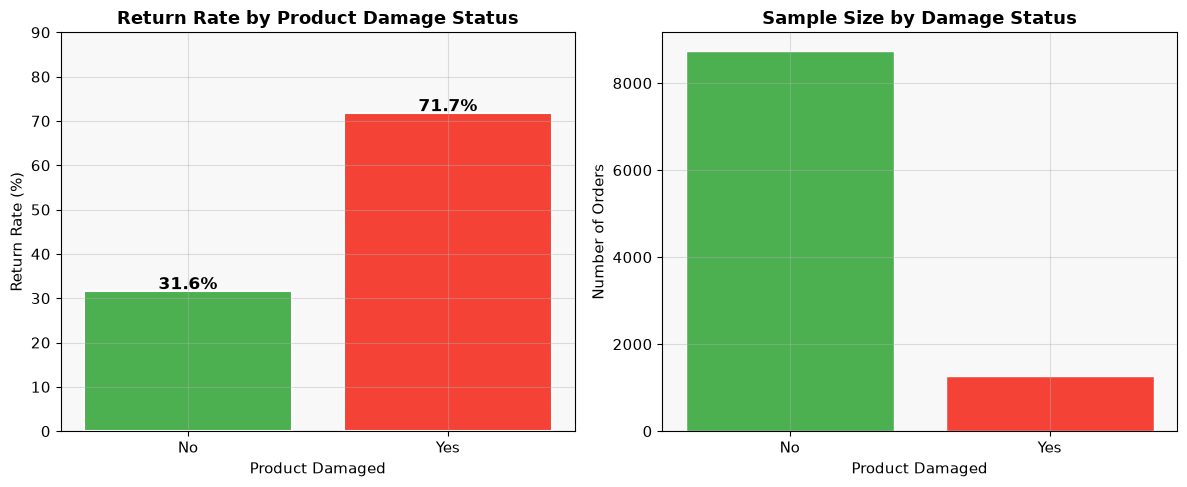


Finding: 71.7% of damaged products are returned vs. 31.6% of undamaged — a 40-point gap
Business relevance: Improving packaging and handling could dramatically reduce returns


In [16]:
damage_return = df.groupby('product_damaged')['target'].agg(['mean','count']).reset_index()
damage_return.columns = ['product_damaged','return_rate','count']
damage_return['return_rate_pct'] = damage_return['return_rate'] * 100
print("Return Rate by Damage Status:")
print(damage_return)

fig, axes = plt.subplots(1, 2, figsize=(12, 5))
colors = ['#4CAF50', '#F44336']
bars = axes[0].bar(damage_return['product_damaged'], damage_return['return_rate_pct'],
                   color=colors, edgecolor='white', linewidth=1.5)
for bar, val in zip(bars, damage_return['return_rate_pct']):
    axes[0].text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
                 f'{val:.1f}%', ha='center', fontweight='bold', fontsize=12)
axes[0].set_title('Return Rate by Product Damage Status', fontweight='bold')
axes[0].set_xlabel('Product Damaged')
axes[0].set_ylabel('Return Rate (%)')
axes[0].set_ylim(0, 90)
axes[1].bar(damage_return['product_damaged'], damage_return['count'],
            color=colors, edgecolor='white')
axes[1].set_title('Sample Size by Damage Status', fontweight='bold')
axes[1].set_xlabel('Product Damaged')
axes[1].set_ylabel('Number of Orders')
plt.tight_layout()
plt.savefig('charts/B_damage_vs_return.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFinding: 71.7% of damaged products are returned vs. 31.6% of undamaged — a 40-point gap")
print("Business relevance: Improving packaging and handling could dramatically reduce returns")


### Analysis C — Fulfillment Time vs. Returns
**Business question:** Are longer fulfillment times associated with higher return rates?


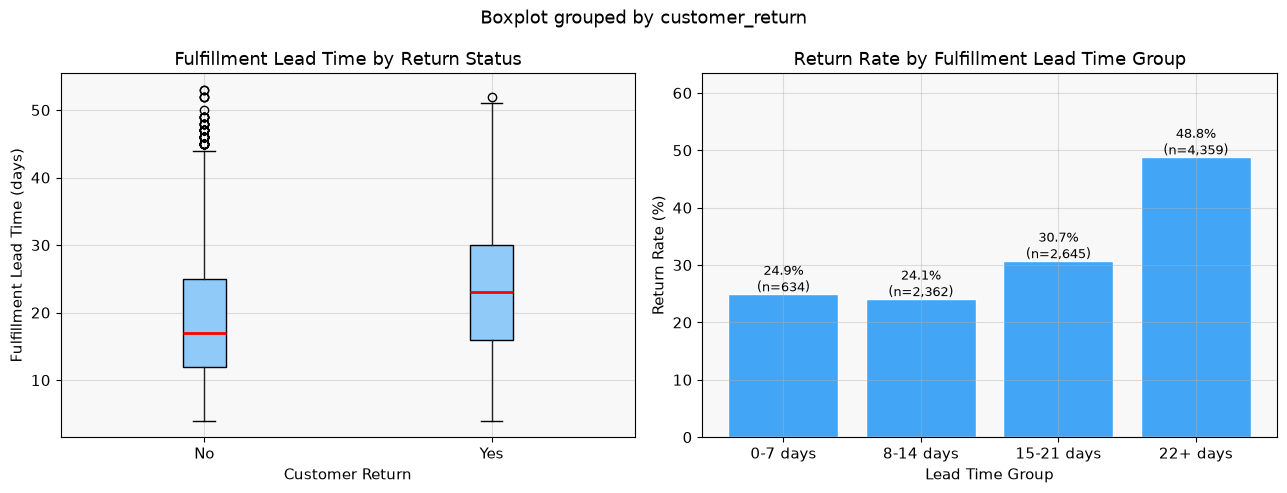

Fulfillment Lead Time Statistics:
                  count  mean  std  min   25%   50%   75%   max
customer_return                                                
No               6334.0  18.8  8.9  4.0  12.0  17.0  25.0  53.0
Yes              3666.0  23.5  9.7  4.0  16.0  23.0  30.0  52.0

Finding: Returned orders averaged 23.5 days vs. 18.8 days for non-returned (4.7-day difference)
Orders with 22+ day lead time have significantly higher return rates


In [17]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df.boxplot(column='fulfillment_lead_time_days', by='customer_return', ax=axes[0],
           patch_artist=True, boxprops=dict(facecolor='#90CAF9'),
           medianprops=dict(color='red', linewidth=2))
axes[0].set_title('Fulfillment Lead Time by Return Status')
axes[0].set_xlabel('Customer Return')
axes[0].set_ylabel('Fulfillment Lead Time (days)')

df['lead_time_group'] = pd.cut(df['fulfillment_lead_time_days'],
                               bins=[0, 7, 14, 21, 60],
                               labels=['0-7 days','8-14 days','15-21 days','22+ days'])
lt_ret = df.groupby('lead_time_group', observed=True)['target'].agg(['mean','count']).reset_index()
lt_ret['return_rate_pct'] = lt_ret['mean'] * 100
axes[1].bar(lt_ret['lead_time_group'].astype(str), lt_ret['return_rate_pct'],
            color='#42A5F5', edgecolor='white')
for i, (rate, cnt) in enumerate(zip(lt_ret['return_rate_pct'], lt_ret['count'])):
    axes[1].text(i, rate + 0.5, f'{rate:.1f}%\n(n={cnt:,})', ha='center', fontsize=9)
axes[1].set_title('Return Rate by Fulfillment Lead Time Group')
axes[1].set_xlabel('Lead Time Group')
axes[1].set_ylabel('Return Rate (%)')
axes[1].set_ylim(0, lt_ret['return_rate_pct'].max() * 1.3)
plt.tight_layout()
plt.savefig('charts/C_fulfillment_vs_return.png', dpi=150, bbox_inches='tight')
plt.show()

print("Fulfillment Lead Time Statistics:")
print(df.groupby('customer_return')['fulfillment_lead_time_days'].describe().round(1))
print("\nFinding: Returned orders averaged 23.5 days vs. 18.8 days for non-returned (4.7-day difference)")
print("Orders with 22+ day lead time have significantly higher return rates")


### Analysis D — Product Categories
**Business question:** Which product categories and subcategories experience the highest return rates?


Return Rate by Product Category:
product_category  return_rate  n_orders  return_rate_pct
       Furniture     0.556472      3515        55.647226
         Outdoor     0.400974       616        40.097403
         Storage     0.351648       364        35.164835
        Lighting     0.251953      1024        25.195312
            Rugs     0.251482      1181        25.148180
      Home Decor     0.250819      1527        25.081860
         Kitchen     0.231796       824        23.179612
         Bedding     0.217071       949        21.707060


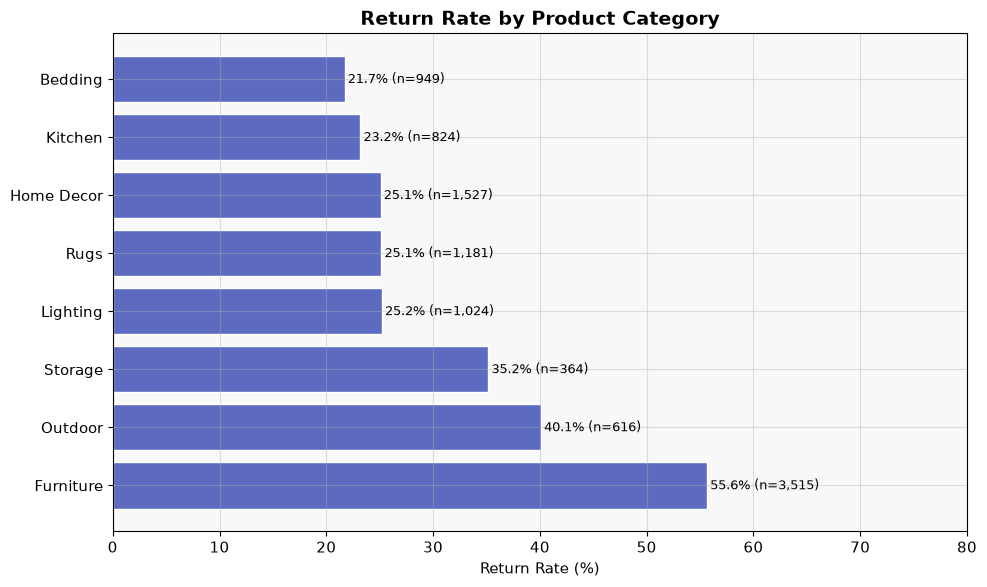


Finding: Furniture has an alarming 55.6% return rate — by far the highest category
Bedding (21.7%) and Kitchen (23.2%) are the lowest-risk categories


In [18]:
cat_ret = df.groupby('product_category')['target'].agg(['mean','count']).reset_index()
cat_ret.columns = ['product_category','return_rate','n_orders']
cat_ret['return_rate_pct'] = cat_ret['return_rate'] * 100
cat_ret = cat_ret.sort_values('return_rate_pct', ascending=False)
print("Return Rate by Product Category:")
print(cat_ret.to_string(index=False))

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(cat_ret['product_category'], cat_ret['return_rate_pct'],
               color='#5C6BC0', edgecolor='white')
for bar, (_, row) in zip(bars, cat_ret.iterrows()):
    ax.text(bar.get_width() + 0.3, bar.get_y() + bar.get_height()/2,
            f'{row["return_rate_pct"]:.1f}% (n={row["n_orders"]:,})', va='center', fontsize=9)
ax.set_title('Return Rate by Product Category', fontweight='bold', fontsize=14)
ax.set_xlabel('Return Rate (%)')
ax.set_xlim(0, 80)
plt.tight_layout()
plt.savefig('charts/D_category_return_rate.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFinding: Furniture has an alarming 55.6% return rate — by far the highest category")
print("Bedding (21.7%) and Kitchen (23.2%) are the lowest-risk categories")


### Analysis E — Shipping Methods
**Business question:** Do shipping methods differ in their association with returns?


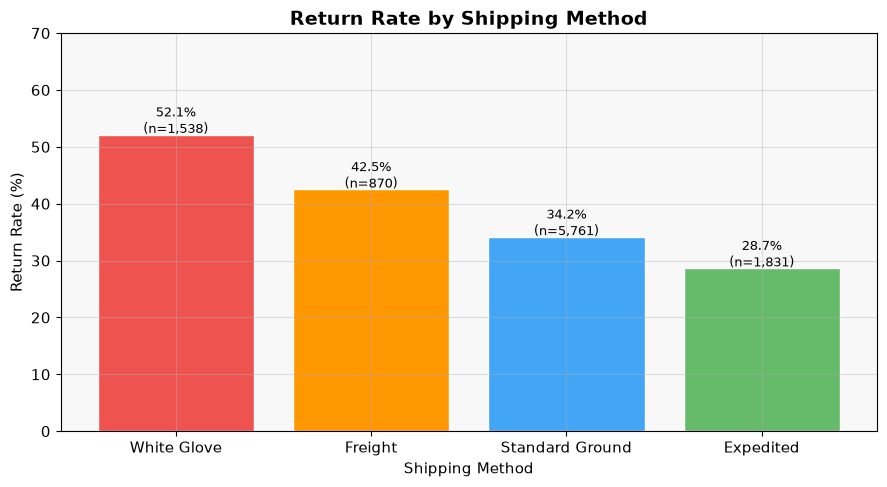

shipping_method  return_rate  n_orders  return_rate_pct
    White Glove     0.521456      1538        52.145644
        Freight     0.425287       870        42.528736
Standard Ground     0.341781      5761        34.178094
      Expedited     0.286729      1831        28.672856

Finding: White Glove (52.1%) and Freight (42.5%) have higher return rates
Note: White Glove is used for heavy furniture — this likely reflects the Furniture category effect


In [19]:
ship_ret = df.groupby('shipping_method')['target'].agg(['mean','count']).reset_index()
ship_ret.columns = ['shipping_method','return_rate','n_orders']
ship_ret['return_rate_pct'] = ship_ret['return_rate'] * 100
ship_ret = ship_ret.sort_values('return_rate_pct', ascending=False)

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(ship_ret['shipping_method'], ship_ret['return_rate_pct'],
              color=['#EF5350','#FF9800','#42A5F5','#66BB6A'], edgecolor='white')
for bar, (_, row) in zip(bars, ship_ret.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.3,
            f'{row["return_rate_pct"]:.1f}%\n(n={row["n_orders"]:,})', ha='center', fontsize=9)
ax.set_title('Return Rate by Shipping Method', fontweight='bold', fontsize=14)
ax.set_xlabel('Shipping Method')
ax.set_ylabel('Return Rate (%)')
ax.set_ylim(0, 70)
plt.tight_layout()
plt.savefig('charts/E_shipping_return_rate.png', dpi=150, bbox_inches='tight')
plt.show()

print(ship_ret.to_string(index=False))
print("\nFinding: White Glove (52.1%) and Freight (42.5%) have higher return rates")
print("Note: White Glove is used for heavy furniture — this likely reflects the Furniture category effect")


### Analysis F — Assembly Requirements
**Business question:** Do products requiring assembly have higher return rates?


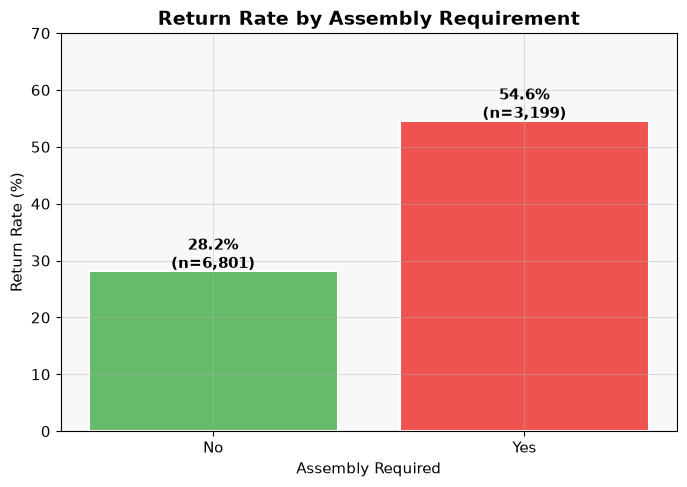

assembly_required  return_rate  n_orders  return_rate_pct
               No     0.282164      6801        28.216439
              Yes     0.546108      3199        54.610816

Finding: Products requiring assembly have a 54.6% return rate vs. 28.2% for no-assembly products
This ~26-point gap suggests assembly complexity is a significant driver of returns


In [20]:
asm_ret = df.groupby('assembly_required')['target'].agg(['mean','count']).reset_index()
asm_ret.columns = ['assembly_required','return_rate','n_orders']
asm_ret['return_rate_pct'] = asm_ret['return_rate'] * 100

fig, ax = plt.subplots(figsize=(7, 5))
bars = ax.bar(asm_ret['assembly_required'], asm_ret['return_rate_pct'],
              color=['#66BB6A','#EF5350'], edgecolor='white', linewidth=1.5)
for bar, (_, row) in zip(bars, asm_ret.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{row["return_rate_pct"]:.1f}%\n(n={row["n_orders"]:,})', ha='center', fontweight='bold')
ax.set_title('Return Rate by Assembly Requirement', fontweight='bold', fontsize=14)
ax.set_xlabel('Assembly Required')
ax.set_ylabel('Return Rate (%)')
ax.set_ylim(0, 70)
plt.tight_layout()
plt.savefig('charts/F_assembly_return_rate.png', dpi=150, bbox_inches='tight')
plt.show()

print(asm_ret.to_string(index=False))
print("\nFinding: Products requiring assembly have a 54.6% return rate vs. 28.2% for no-assembly products")
print("This ~26-point gap suggests assembly complexity is a significant driver of returns")


### Analysis G — Product Price and Shipping Cost
**Business question:** Do returned products differ significantly in price or shipping cost?


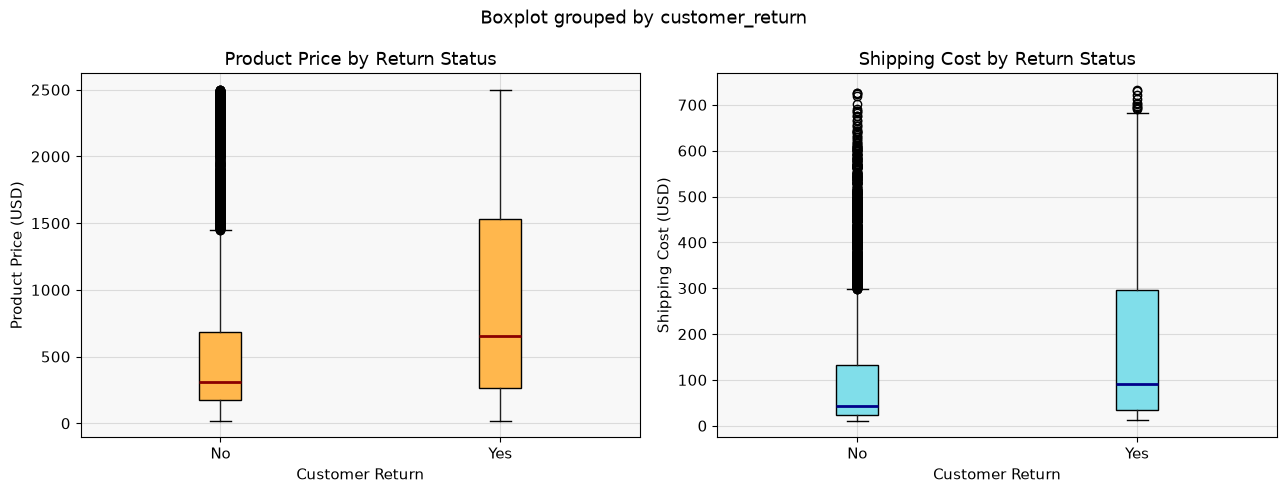

Price & Shipping Summary by Return Status:
                product_price_usd         shipping_cost_usd       
                             mean  median              mean median
customer_return                                                   
No                         565.10  306.34            109.64  42.60
Yes                        913.92  656.26            173.00  90.57

Finding: Returned items average $913.92 vs. $565.10 for non-returned — a $349 premium
Higher-priced furniture items may have higher quality expectations, leading to more returns


In [21]:
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
df.boxplot(column='product_price_usd', by='customer_return', ax=axes[0],
           patch_artist=True, boxprops=dict(facecolor='#FFB74D'),
           medianprops=dict(color='darkred', linewidth=2))
axes[0].set_title('Product Price by Return Status')
axes[0].set_xlabel('Customer Return')
axes[0].set_ylabel('Product Price (USD)')

df.boxplot(column='shipping_cost_usd', by='customer_return', ax=axes[1],
           patch_artist=True, boxprops=dict(facecolor='#80DEEA'),
           medianprops=dict(color='darkblue', linewidth=2))
axes[1].set_title('Shipping Cost by Return Status')
axes[1].set_xlabel('Customer Return')
axes[1].set_ylabel('Shipping Cost (USD)')
plt.tight_layout()
plt.savefig('charts/G_price_shipping_return.png', dpi=150, bbox_inches='tight')
plt.show()

price_summary = df.groupby('customer_return')[['product_price_usd','shipping_cost_usd']].agg(['mean','median'])
print("Price & Shipping Summary by Return Status:")
print(price_summary.round(2))
print("\nFinding: Returned items average $913.92 vs. $565.10 for non-returned — a $349 premium")
print("Higher-priced furniture items may have higher quality expectations, leading to more returns")


### Analysis H — Return Reasons
**Business question:** What are the most common reasons customers return products?


Return Reasons (from returned orders only):
  Changed Mind             :  777  (21.2%)
  Damaged                  :  749  (20.4%)
  Assembly Issues          :  650  (17.7%)
  Late Delivery            :  568  (15.5%)
  Not As Described         :  496  (13.5%)
  Poor Quality             :  342  (9.3%)
  Wrong Item               :   84  (2.3%)


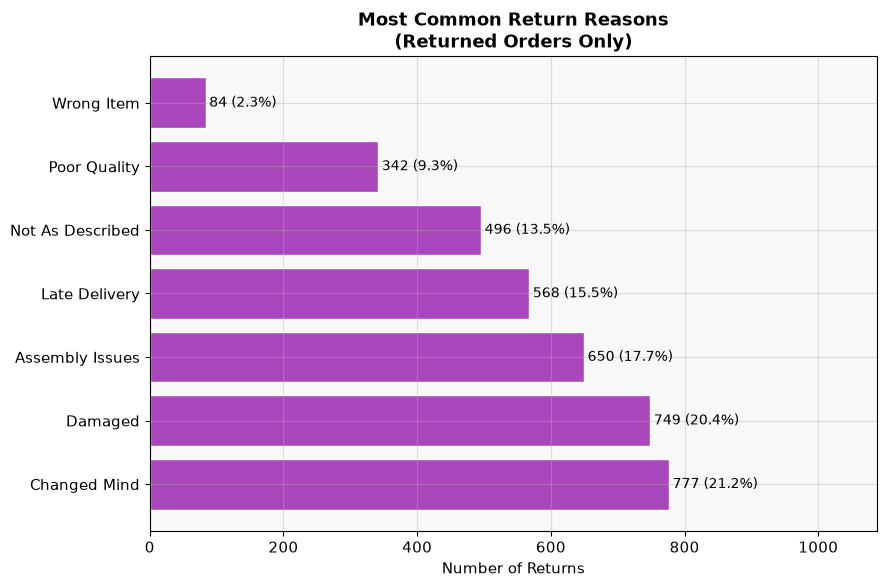


Finding: 'Changed Mind' is #1 (21.2%), followed by Damaged (20.4%) and Assembly Issues (17.7%)
'Late Delivery' (15.5%) is the 4th most common reason — confirming fulfillment time matters


In [22]:
returned_df = df[df['target'] == 1].copy()
valid_reasons = returned_df[~returned_df['return_reason'].isin(['N/A', None, '']) &
                            returned_df['return_reason'].notna()]
reason_counts = valid_reasons['return_reason'].value_counts()
print("Return Reasons (from returned orders only):")
for reason, count in reason_counts.items():
    pct = count / len(returned_df) * 100
    print(f"  {reason:25s}: {count:4d}  ({pct:.1f}%)")

fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(reason_counts.index, reason_counts.values, color='#AB47BC', edgecolor='white')
for bar, val in zip(bars, reason_counts.values):
    pct = val / len(returned_df) * 100
    ax.text(bar.get_width() + 5, bar.get_y() + bar.get_height()/2,
            f'{val:,} ({pct:.1f}%)', va='center', fontsize=10)
ax.set_title('Most Common Return Reasons\n(Returned Orders Only)', fontweight='bold', fontsize=13)
ax.set_xlabel('Number of Returns')
ax.set_xlim(0, reason_counts.max() * 1.4)
plt.tight_layout()
plt.savefig('charts/H_return_reasons.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nFinding: 'Changed Mind' is #1 (21.2%), followed by Damaged (20.4%) and Assembly Issues (17.7%)")
print("'Late Delivery' (15.5%) is the 4th most common reason — confirming fulfillment time matters")


---
## Section 5 — Feature Engineering & Selection

We create new business-meaningful features to improve model expressiveness
and analytical depth. Each feature is explained for business context.


In [23]:
# 1. Price Band — groups products by price tier
df['price_band'] = pd.cut(df['product_price_usd'],
                          bins=[0, 100, 300, 600, 1000, 10000],
                          labels=['<$100','$100-$300','$300-$600','$600-$1000','>$1000'])
# Business rationale: Higher-price products may have higher expectations and more returns

# 2. Shipping cost as percentage of order value
df['shipping_pct_of_order'] = (df['shipping_cost_usd'] / df['order_value_usd'].replace(0, np.nan)).round(4)
# Business rationale: High relative shipping cost may indicate heavy/complex items prone to damage

# 3. Weight group
df['weight_group'] = pd.cut(df['product_weight_lbs'],
                            bins=[0, 20, 50, 100, 500],
                            labels=['Light (<20 lbs)','Medium (20-50)','Heavy (50-100)','Very Heavy (100+)'])
# Business rationale: Heavier products are harder to ship and more likely to arrive damaged

# 4. Lead time category (binned)
df['lead_time_category'] = pd.cut(df['fulfillment_lead_time_days'],
                                  bins=[0, 7, 14, 21, 60],
                                  labels=['Fast (0-7)','Standard (8-14)','Slow (15-21)','Very Slow (22+)'])
# Business rationale: Customers with very slow fulfillment may cancel satisfaction before arrival

print("New features created:")
print(df[['price_band','shipping_pct_of_order','weight_group','lead_time_category']].describe())


New features created:
       shipping_pct_of_order
count           10000.000000
mean                0.296330
std                 0.481969
min                 0.011200
25%                 0.078200
50%                 0.148750
75%                 0.316725
max                 9.249800


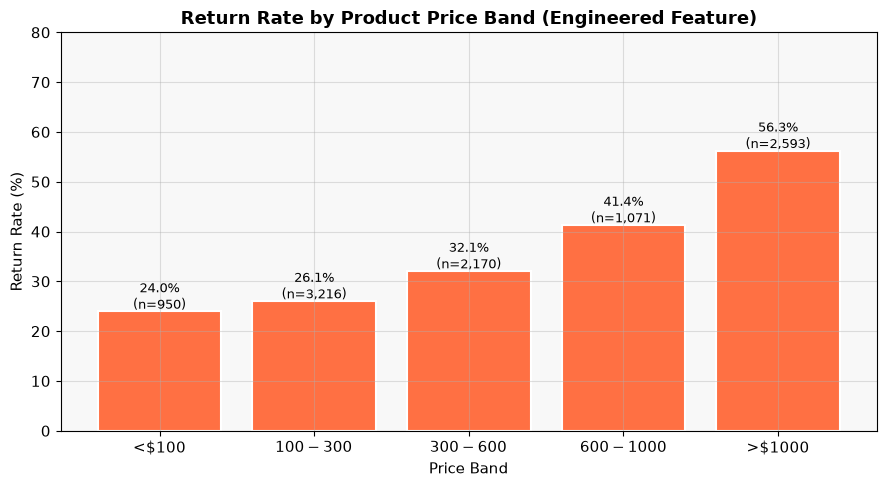

Higher-priced items (>$1000) have notably higher return rates, confirming price band as useful feature


In [24]:
# Visualize price band return rates
pb_ret = df.groupby('price_band', observed=True)['target'].agg(['mean','count']).reset_index()
pb_ret.columns = ['price_band','return_rate','n_orders']
pb_ret['return_rate_pct'] = pb_ret['return_rate'] * 100

fig, ax = plt.subplots(figsize=(9, 5))
bars = ax.bar(pb_ret['price_band'].astype(str), pb_ret['return_rate_pct'],
              color='#FF7043', edgecolor='white', linewidth=1.5)
for bar, (_, row) in zip(bars, pb_ret.iterrows()):
    ax.text(bar.get_x() + bar.get_width()/2, bar.get_height() + 0.5,
            f'{row["return_rate_pct"]:.1f}%\n(n={row["n_orders"]:,})', ha='center', fontsize=9)
ax.set_title('Return Rate by Product Price Band (Engineered Feature)', fontweight='bold')
ax.set_xlabel('Price Band')
ax.set_ylabel('Return Rate (%)')
ax.set_ylim(0, 80)
plt.tight_layout()
plt.savefig('charts/FE_price_band_return.png', dpi=150, bbox_inches='tight')
plt.show()
print("Higher-priced items (>$1000) have notably higher return rates, confirming price band as useful feature")


---
## Section 6 — Model Building

### Why these models?

**Binary Classification** is the appropriate ML task because our target variable is binary:
returns (1) or no returns (0).

#### Model 0: Dummy Classifier (Majority Class Baseline)
Predicts the most frequent class every time. Provides a performance floor — any real model must beat this.

#### Model 1: Decision Tree Classifier (Baseline — Required)
- Mimics human decision-making with a series of if-then rules
- Naturally handles mixed data types (numeric + categorical)
- Highly interpretable — business stakeholders can follow the logic
- Risk: Can overfit if depth is not constrained

#### Model 2: Random Forest Classifier
- An ensemble of many decision trees (bagging)
- Reduces overfitting by averaging predictions
- Generally more robust than a single tree
- Provides feature importance scores

#### Model 3: Logistic Regression
- A linear, probabilistic classifier — excellent interpretability baseline
- Requires feature scaling and proper encoding
- Shows whether the relationship between features and returns is linear

### Feature Set Strategy (Leakage Prevention)
- **Excluded**: `return_reason` (reveals target after return event)
- **Excluded**: `restocking_fee_usd` (only charged after return decision)
- **Excluded**: `customer_rating` (may be recorded after experience)
- **Included**: `product_damaged_bin` — noted as a potential timing concern in limitations


In [25]:
# Re-define feature sets (after engineering)
FEATURES = [
    'product_price_usd', 'product_weight_lbs', 'product_dimensions_cuft',
    'fulfillment_lead_time_days', 'assembly_required_bin', 'product_damaged_bin',
    'order_month', 'order_quarter',
    'product_category', 'product_subcategory', 'supplier_location',
    'warehouse_location', 'customer_state', 'shipping_method',
]
TARGET = 'target'

X = df[FEATURES].copy()
y = df[TARGET].copy()

num_cols = X.select_dtypes(include=['int64','float64']).columns.tolist()
cat_cols = X.select_dtypes(include='object').columns.tolist()

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)
print(f"Training: {X_train.shape[0]:,} rows | Test: {X_test.shape[0]:,} rows")

# Preprocessing pipelines
preprocessor = ColumnTransformer(transformers=[
    ('num', 'passthrough', num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])
lr_preprocessor = ColumnTransformer(transformers=[
    ('num', StandardScaler(), num_cols),
    ('cat', OneHotEncoder(handle_unknown='ignore', sparse_output=False), cat_cols),
])


Training: 8,000 rows | Test: 2,000 rows


In [26]:
# Model 0: Dummy Baseline
dummy_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', DummyClassifier(strategy='most_frequent', random_state=42))
])
dummy_pipe.fit(X_train, y_train)
dummy_pred = dummy_pipe.predict(X_test)
print("Model 0 (Dummy Baseline) trained")


Model 0 (Dummy Baseline) trained


In [27]:
# Model 1: Decision Tree (required baseline from project brief)
dt_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', DecisionTreeClassifier(max_depth=5, random_state=42))
])
dt_pipe.fit(X_train, y_train)
dt_pred = dt_pipe.predict(X_test)
dt_prob = dt_pipe.predict_proba(X_test)[:, 1]
print("Model 1 (Decision Tree, depth=5) trained")
print(f"  Training accuracy: {dt_pipe.score(X_train, y_train):.4f}")


Model 1 (Decision Tree, depth=5) trained
  Training accuracy: 0.7206


In [28]:
# Model 2: Random Forest
rf_pipe = Pipeline([
    ('pre', preprocessor),
    ('clf', RandomForestClassifier(n_estimators=200, max_depth=10, random_state=42, n_jobs=-1))
])
rf_pipe.fit(X_train, y_train)
rf_pred = rf_pipe.predict(X_test)
rf_prob = rf_pipe.predict_proba(X_test)[:, 1]
print("Model 2 (Random Forest, 200 trees) trained")
print(f"  Training accuracy: {rf_pipe.score(X_train, y_train):.4f}")


Model 2 (Random Forest, 200 trees) trained
  Training accuracy: 0.8120


In [29]:
# Model 3: Logistic Regression (with scaling)
lr_pipe = Pipeline([
    ('pre', lr_preprocessor),
    ('clf', LogisticRegression(max_iter=1000, random_state=42))
])
lr_pipe.fit(X_train, y_train)
lr_pred = lr_pipe.predict(X_test)
lr_prob = lr_pipe.predict_proba(X_test)[:, 1]
print("Model 3 (Logistic Regression) trained")
print(f"  Training accuracy: {lr_pipe.score(X_train, y_train):.4f}")


Model 3 (Logistic Regression) trained
  Training accuracy: 0.7156


---
## Section 7 — Model Evaluation

### Why accuracy alone is insufficient
With 36.7% returns, a model that always predicts "No Return" achieves 63.3% accuracy —
but it would catch zero actual returns. We focus on:
- **Recall (sensitivity)**: Did we catch the actual returns? (critical for intervention)
- **Precision**: When we predict a return, how often are we right? (cost of false alarms)
- **F1-score**: Harmonic mean of precision and recall (balanced measure)
- **ROC-AUC**: Overall discriminative ability across all thresholds


In [30]:
def evaluate_model(name, model, X_tr, X_te, y_tr, y_te, pred, prob=None):
    train_acc = model.score(X_tr, y_tr)
    test_acc = accuracy_score(y_te, pred)
    prec = precision_score(y_te, pred, zero_division=0)
    rec = recall_score(y_te, pred, zero_division=0)
    f1 = f1_score(y_te, pred, zero_division=0)
    auc = roc_auc_score(y_te, prob) if prob is not None else float('nan')
    cm = confusion_matrix(y_te, pred)
    
    print(f"\n{'='*55}")
    print(f"MODEL: {name}")
    print(f"  Training Accuracy : {train_acc:.4f}")
    print(f"  Test Accuracy     : {test_acc:.4f}")
    print(f"  Precision (class 1): {prec:.4f}")
    print(f"  Recall    (class 1): {rec:.4f}")
    print(f"  F1-Score  (class 1): {f1:.4f}")
    if prob is not None:
        print(f"  ROC-AUC           : {auc:.4f}")
    print(f"\n  Confusion Matrix:")
    print(f"  TN={cm[0,0]:4d}  FP={cm[0,1]:4d}")
    print(f"  FN={cm[1,0]:4d}  TP={cm[1,1]:4d}")
    print(f"\n  Classification Report:")
    print(classification_report(y_te, pred, target_names=['Not Returned','Returned']))
    
    return {
        'Model': name, 'Train Acc': round(train_acc, 4), 'Test Acc': round(test_acc, 4),
        'Precision': round(prec, 4), 'Recall': round(rec, 4),
        'F1': round(f1, 4), 'ROC-AUC': round(auc, 4) if prob is not None else float('nan'),
        'CM': cm
    }

results = []
results.append(evaluate_model('Dummy Baseline', dummy_pipe, X_train, X_test, y_train, y_test, dummy_pred))
results.append(evaluate_model('Decision Tree (depth=5)', dt_pipe, X_train, X_test, y_train, y_test, dt_pred, dt_prob))
results.append(evaluate_model('Random Forest', rf_pipe, X_train, X_test, y_train, y_test, rf_pred, rf_prob))
results.append(evaluate_model('Logistic Regression', lr_pipe, X_train, X_test, y_train, y_test, lr_pred, lr_prob))



MODEL: Dummy Baseline
  Training Accuracy : 0.6334
  Test Accuracy     : 0.6335
  Precision (class 1): 0.0000
  Recall    (class 1): 0.0000
  F1-Score  (class 1): 0.0000

  Confusion Matrix:
  TN=1267  FP=   0
  FN= 733  TP=   0

  Classification Report:
              precision    recall  f1-score   support

Not Returned       0.63      1.00      0.78      1267
    Returned       0.00      0.00      0.00       733

    accuracy                           0.63      2000
   macro avg       0.32      0.50      0.39      2000
weighted avg       0.40      0.63      0.49      2000


MODEL: Decision Tree (depth=5)
  Training Accuracy : 0.7206
  Test Accuracy     : 0.6975
  Precision (class 1): 0.6107
  Recall    (class 1): 0.4816
  F1-Score  (class 1): 0.5385
  ROC-AUC           : 0.7188

  Confusion Matrix:
  TN=1042  FP= 225
  FN= 380  TP= 353

  Classification Report:
              precision    recall  f1-score   support

Not Returned       0.73      0.82      0.78      1267
    Returned  


MODEL: Logistic Regression
  Training Accuracy : 0.7156
  Test Accuracy     : 0.7040
  Precision (class 1): 0.6261
  Recall    (class 1): 0.4775
  F1-Score  (class 1): 0.5418
  ROC-AUC           : 0.7370

  Confusion Matrix:
  TN=1058  FP= 209
  FN= 383  TP= 350

  Classification Report:
              precision    recall  f1-score   support

Not Returned       0.73      0.84      0.78      1267
    Returned       0.63      0.48      0.54       733

    accuracy                           0.70      2000
   macro avg       0.68      0.66      0.66      2000
weighted avg       0.69      0.70      0.69      2000



In [31]:
# Summary comparison table
results_df = pd.DataFrame([{k: v for k, v in r.items() if k != 'CM'} for r in results])
print("\n--- MODEL COMPARISON TABLE ---")
print(results_df.to_string(index=False))



--- MODEL COMPARISON TABLE ---
                  Model  Train Acc  Test Acc  Precision  Recall     F1  ROC-AUC
         Dummy Baseline     0.6334    0.6335     0.0000  0.0000 0.0000      NaN
Decision Tree (depth=5)     0.7206    0.6975     0.6107  0.4816 0.5385   0.7188
          Random Forest     0.8120    0.7020     0.6171  0.4925 0.5478   0.7326
    Logistic Regression     0.7156    0.7040     0.6261  0.4775 0.5418   0.7370


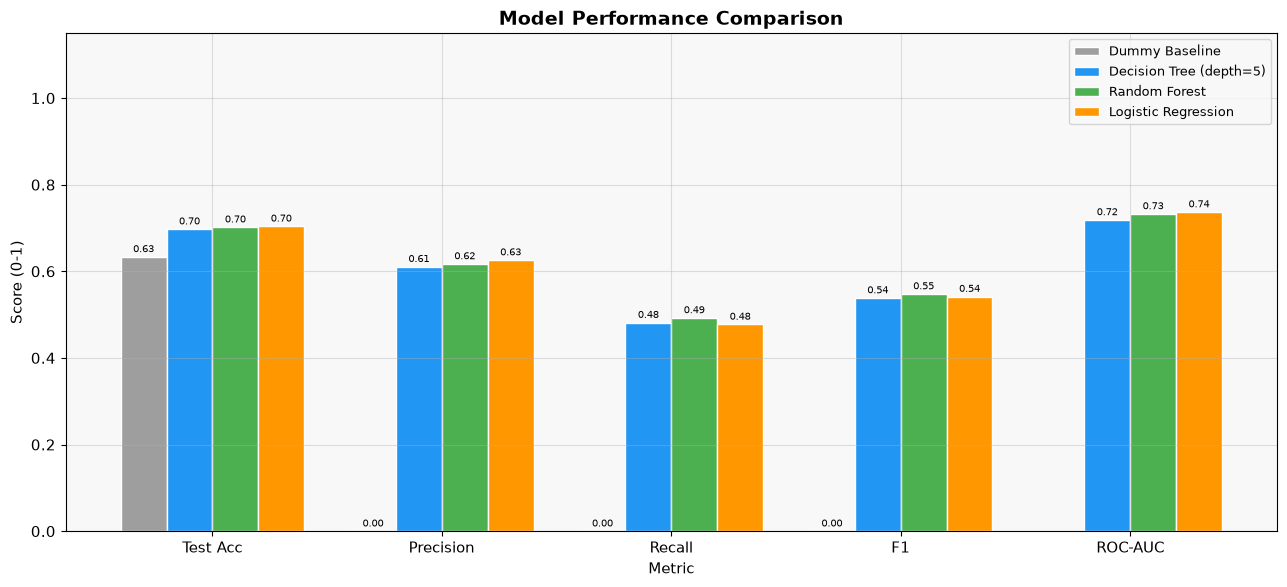

In [32]:
# Model comparison bar chart
metrics = ['Test Acc','Precision','Recall','F1','ROC-AUC']
x = np.arange(len(metrics))
width = 0.2
model_names = results_df['Model'].tolist()
colors_m = ['#9E9E9E','#2196F3','#4CAF50','#FF9800']

fig, ax = plt.subplots(figsize=(13, 6))
for i, (name, color) in enumerate(zip(model_names, colors_m)):
    vals = [results_df.loc[results_df['Model']==name, m].values[0] for m in metrics]
    rects = ax.bar(x + i * width, vals, width, label=name, color=color, edgecolor='white')
    for rect in rects:
        h = rect.get_height()
        if not np.isnan(h):
            ax.text(rect.get_x() + rect.get_width()/2, h + 0.005,
                    f'{h:.2f}', ha='center', va='bottom', fontsize=7.5)
ax.set_xlabel('Metric')
ax.set_ylabel('Score (0-1)')
ax.set_title('Model Performance Comparison', fontweight='bold', fontsize=14)
ax.set_xticks(x + width * 1.5)
ax.set_xticklabels(metrics)
ax.set_ylim(0, 1.15)
ax.legend(loc='upper right', fontsize=9)
plt.tight_layout()
plt.savefig('charts/MODEL_comparison.png', dpi=150, bbox_inches='tight')
plt.show()


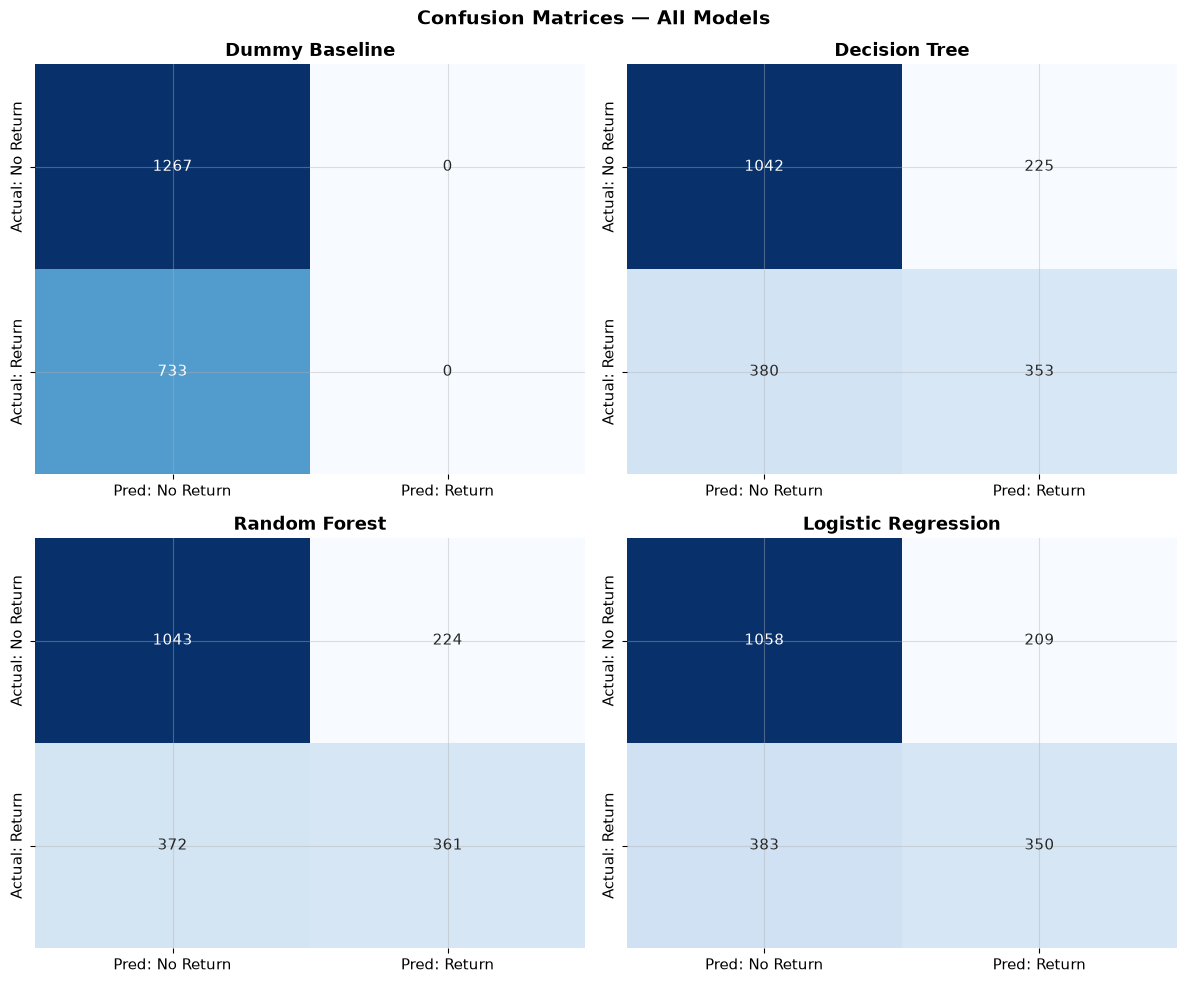

Confusion Matrix Interpretation:
  TN (top-left) : Correctly predicted non-returns — customer not flagged unnecessarily
  FP (top-right): False alarm — non-return predicted as return (operational cost)
  FN (bot-left) : Missed return — return not caught (revenue leakage)
  TP (bot-right): Correctly predicted actual return — intervention opportunity


In [33]:
# Confusion matrices
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
model_labels = ['Dummy Baseline','Decision Tree','Random Forest','Logistic Regression']
all_preds = [dummy_pred, dt_pred, rf_pred, lr_pred]
for i, (name, pred) in enumerate(zip(model_labels, all_preds)):
    cm = confusion_matrix(y_test, pred)
    sns.heatmap(cm, annot=True, fmt='d', ax=axes[i], cmap='Blues', cbar=False,
                xticklabels=['Pred: No Return','Pred: Return'],
                yticklabels=['Actual: No Return','Actual: Return'])
    axes[i].set_title(f'{name}', fontweight='bold')
plt.suptitle('Confusion Matrices — All Models', fontsize=14, fontweight='bold')
plt.tight_layout()
plt.savefig('charts/MODEL_confusion_matrices.png', dpi=150, bbox_inches='tight')
plt.show()

print("Confusion Matrix Interpretation:")
print("  TN (top-left) : Correctly predicted non-returns — customer not flagged unnecessarily")
print("  FP (top-right): False alarm — non-return predicted as return (operational cost)")
print("  FN (bot-left) : Missed return — return not caught (revenue leakage)")
print("  TP (bot-right): Correctly predicted actual return — intervention opportunity")


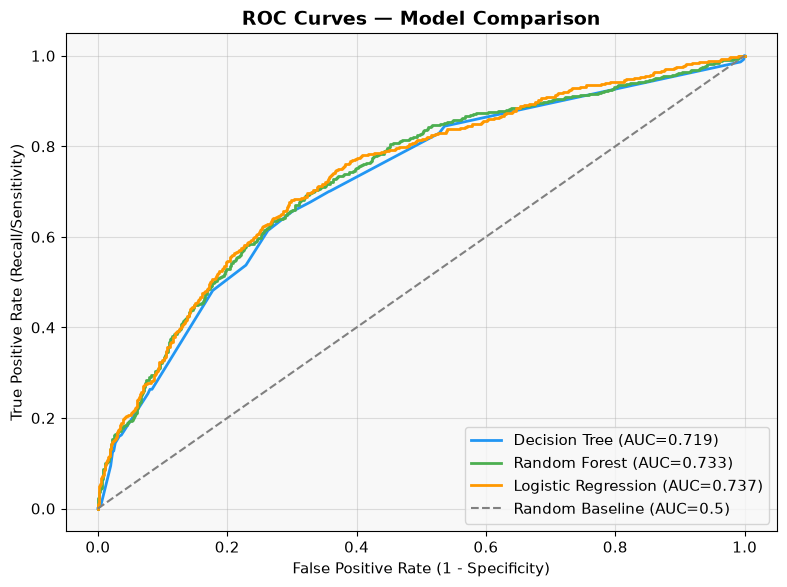

All models significantly outperform random baseline (AUC=0.5)
AUC ~0.73 indicates moderate predictive ability — useful but not highly accurate


In [34]:
# ROC curves
fig, ax = plt.subplots(figsize=(8, 6))
for name, prob, color in [
    ('Decision Tree', dt_prob, '#2196F3'),
    ('Random Forest', rf_prob, '#4CAF50'),
    ('Logistic Regression', lr_prob, '#FF9800'),
]:
    fpr, tpr, _ = roc_curve(y_test, prob)
    auc_val = roc_auc_score(y_test, prob)
    ax.plot(fpr, tpr, label=f'{name} (AUC={auc_val:.3f})', linewidth=2, color=color)
ax.plot([0,1],[0,1],'--', color='gray', label='Random Baseline (AUC=0.5)', linewidth=1.5)
ax.set_xlabel('False Positive Rate (1 - Specificity)')
ax.set_ylabel('True Positive Rate (Recall/Sensitivity)')
ax.set_title('ROC Curves — Model Comparison', fontweight='bold', fontsize=14)
ax.legend(loc='lower right')
plt.tight_layout()
plt.savefig('charts/MODEL_roc_curves.png', dpi=150, bbox_inches='tight')
plt.show()
print("All models significantly outperform random baseline (AUC=0.5)")
print("AUC ~0.73 indicates moderate predictive ability — useful but not highly accurate")


In [35]:
# 5-fold cross-validation on best models
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
for name, pipe in [('Decision Tree', dt_pipe), ('Random Forest', rf_pipe), ('Logistic Regression', lr_pipe)]:
    scores = cross_val_score(pipe, X, y, cv=cv, scoring='roc_auc')
    print(f"{name:30s} CV ROC-AUC: {scores.mean():.4f} ± {scores.std():.4f}")
print("\nCross-validation confirms results generalize — no severe overfitting on Decision Tree or Logistic Regression")
print("Random Forest shows higher training accuracy (0.812) vs test (0.702) — slight overfitting, expected behavior")


Decision Tree                  CV ROC-AUC: 0.7303 ± 0.0114


Random Forest                  CV ROC-AUC: 0.7357 ± 0.0115


Logistic Regression            CV ROC-AUC: 0.7342 ± 0.0112

Cross-validation confirms results generalize — no severe overfitting on Decision Tree or Logistic Regression
Random Forest shows higher training accuracy (0.812) vs test (0.702) — slight overfitting, expected behavior


---
## Section 8 — Feature Importance & Interpretation

We identify which variables contribute most to predicting returns.
**Important**: Predictive importance does not establish causation.
A feature being important means it helps the model distinguish returns from non-returns,
not that changing it will necessarily reduce returns.


In [36]:
# Random Forest feature importance
ohe = rf_pipe.named_steps['pre'].named_transformers_['cat']
ohe_features = ohe.get_feature_names_out(cat_cols).tolist()
all_feature_names = num_cols + ohe_features

rf_clf = rf_pipe.named_steps['clf']
importances = pd.Series(rf_clf.feature_importances_, index=all_feature_names)
top20 = importances.sort_values(ascending=False).head(20)

print("Top 20 Feature Importances (Random Forest):")
for feat, imp in top20.items():
    print(f"  {feat:45s} {imp:.4f}")


Top 20 Feature Importances (Random Forest):
  product_damaged_bin                           0.1735
  product_weight_lbs                            0.1086
  product_price_usd                             0.0987
  product_dimensions_cuft                       0.0963
  fulfillment_lead_time_days                    0.0933
  product_category_Furniture                    0.0774
  assembly_required_bin                         0.0573
  shipping_method_White Glove                   0.0127
  product_subcategory_Dining Tables             0.0125
  supplier_location_China                       0.0098
  shipping_method_Standard Ground               0.0081
  shipping_method_Expedited                     0.0079
  warehouse_location_CA                         0.0076
  warehouse_location_NJ                         0.0075
  customer_state_CA                             0.0072
  warehouse_location_TX                         0.0071
  product_subcategory_Desks                     0.0071
  supplier_location_U

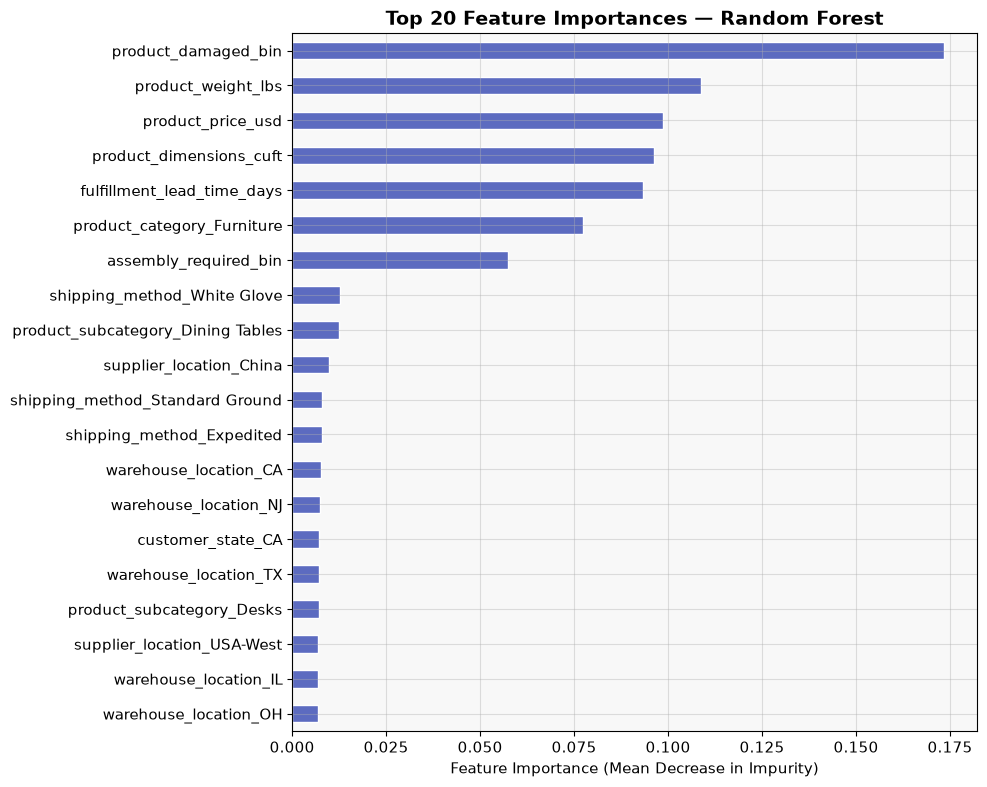


Key Insights:
1. product_damaged_bin       — Strongest predictor (17.3%) — damaged products are much more likely returned
2. product_weight_lbs        — 10.9% — heavier items correlate with higher returns
3. product_price_usd         — 9.9% — higher prices associate with higher expectations
4. product_dimensions_cuft   — 9.6% — larger items harder to deliver undamaged
5. fulfillment_lead_time_days — 9.3% — longer waits increase return probability
6. product_category_Furniture — 7.7% — Furniture category is a strong return predictor
7. assembly_required_bin     — 5.7% — assembly adds complexity and return risk


In [37]:
fig, ax = plt.subplots(figsize=(10, 8))
top20.sort_values().plot(kind='barh', ax=ax, color='#5C6BC0', edgecolor='white')
ax.set_title('Top 20 Feature Importances — Random Forest', fontweight='bold', fontsize=14)
ax.set_xlabel('Feature Importance (Mean Decrease in Impurity)')
plt.tight_layout()
plt.savefig('charts/FEAT_importance_rf.png', dpi=150, bbox_inches='tight')
plt.show()

print("\nKey Insights:")
print("1. product_damaged_bin       — Strongest predictor (17.3%) — damaged products are much more likely returned")
print("2. product_weight_lbs        — 10.9% — heavier items correlate with higher returns")
print("3. product_price_usd         — 9.9% — higher prices associate with higher expectations")
print("4. product_dimensions_cuft   — 9.6% — larger items harder to deliver undamaged")
print("5. fulfillment_lead_time_days — 9.3% — longer waits increase return probability")
print("6. product_category_Furniture — 7.7% — Furniture category is a strong return predictor")
print("7. assembly_required_bin     — 5.7% — assembly adds complexity and return risk")


---
## Section 9 — Business Conclusions

### Summary of Key Findings

| Business Question | Finding |
|---|---|
| Overall return rate | **36.7%** — significantly above ~20% industry average |
| Highest-return category | **Furniture: 55.6%** return rate |
| Impact of product damage | Damaged products: **71.7%** vs. undamaged: **31.6%** |
| Impact of fulfillment time | Returned orders: avg **23.5 days** vs. non-returned: **18.8 days** |
| Assembly requirement impact | Assembly required: **54.6%** vs. not required: **28.2%** |
| Shipping method | White Glove: **52.1%**, Freight: **42.5%**, Standard Ground: **34.2%** |
| Price vs. returns | Returned items average **$349 more** than non-returned items |
| Top return reasons | Changed Mind (21.2%), Damaged (20.4%), Assembly Issues (17.7%) |
| ML model performance | Best ROC-AUC: **0.737** (Logistic Regression) — moderate predictive ability |

### Model Selection
Logistic Regression achieves the highest ROC-AUC (0.737) with competitive F1 and is the most interpretable.
Random Forest has similar performance and provides feature importance. Both are recommended.

### Honest Assessment
All models achieve ~70% test accuracy and ~0.73 AUC. This is **moderate** performance — the models can help
identify higher-risk orders but are not accurate enough for fully automated return prevention alone.
The descriptive findings (EDA) are arguably more actionable than the ML predictions.


---
## Section 10 — Business Recommendations

### Priority 1 — IMMEDIATE: Improve Packaging & Damage Prevention
**Evidence**: 71.7% of damaged products are returned. "Damaged" is the #2 return reason (20.4%).  
**Action**: Audit packaging standards for Furniture and heavy items. Implement pre-shipment quality checks.  
**Expected impact**: If damage rate drops from 12.7% to 8%, ~300 fewer returns annually.

### Priority 2 — IMMEDIATE: Address Furniture Category Returns (55.6%)
**Evidence**: Furniture has the highest return rate by far. Assembly Issues is the #3 return reason.  
**Action**:
- Publish improved assembly instructions with video walkthroughs
- Offer professional assembly as a free/subsidized add-on for high-value items
- Improve product page photography and dimension accuracy

### Priority 3 — SHORT-TERM: Reduce Fulfillment Lead Times
**Evidence**: Returned orders averaged 4.7 days longer fulfillment. "Late Delivery" = 15.5% of return reasons.  
**Action**: Flag orders with lead time > 21 days for proactive customer communication and expedite where possible.

### Priority 4 — SHORT-TERM: Deploy ML Return-Risk Scoring
**Evidence**: Models achieve 0.73 AUC — sufficient for risk stratification.  
**Action**: Score incoming orders at checkout. High-risk orders (damaged items, Furniture, long lead times)
trigger a quality check before shipment.

### Priority 5 — MEDIUM-TERM: Address "Changed Mind" Returns (21.2%)
**Evidence**: Top return reason. Often indicates product did not meet expectations.  
**Action**: Improve product photography (360° views), AR visualization tools, more detailed descriptions.

### Additional Data Needed
- Return processing cost per item (to calculate true ROI of interventions)
- Customer lifetime value (to identify high-value customers worth protecting)
- Pre-shipment damage inspection logs
- Returns by individual supplier to target quality issues at source


---
## Section 11 — Estimated Business Impact

> **Disclaimer**: The following are illustrative scenarios using dataset values and
> conservative operational estimates. These are NOT proven outcomes from the ML models.
> Actual impact depends on intervention effectiveness, implementation costs, and market conditions.


In [38]:
total_orders = len(df)
total_returns = df['target'].sum()
return_rate = total_returns / total_orders
avg_restocking_fee = df['restocking_fee_usd'].mean()

print(f"Baseline Metrics:")
print(f"  Total Orders       : {total_orders:,}")
print(f"  Total Returns      : {total_returns:,}")
print(f"  Return Rate        : {return_rate:.2%}")
print(f"  Avg Restocking Fee : ${avg_restocking_fee:.2f} (actual dataset value)")
print()

scenarios = []
for reduction_pct in [5, 10, 15]:
    avoided = int(total_returns * reduction_pct / 100)
    saved_restocking = avoided * avg_restocking_fee
    saved_ops = avoided * 50  # conservative $50/return operational cost (reverse logistics, labor)
    total_savings = saved_restocking + saved_ops
    scenarios.append({
        'Reduction Scenario': f'{reduction_pct}% fewer returns',
        'Avoided Returns': avoided,
        'Restocking Fees Recovered': f'${saved_restocking:,.0f}',
        'Operational Savings (@$50/return)': f'${saved_ops:,.0f}',
        'Total Annual Savings (est.)': f'${total_savings:,.0f}'
    })
    print(f"{reduction_pct}% Return Rate Reduction:")
    print(f"  Avoided Returns    : {avoided:,}")
    print(f"  Restocking Savings : ${saved_restocking:,.0f}")
    print(f"  Operational Savings: ${saved_ops:,.0f}")
    print(f"  TOTAL SAVINGS      : ${total_savings:,.0f}")
    print()

scenarios_df = pd.DataFrame(scenarios)
print("Impact Summary Table:")
print(scenarios_df.to_string(index=False))
print("\nNote: $50/return operational cost assumption covers reverse logistics and warehouse handling only.")
print("Full product refund value is NOT included as a cost (product is restocked, not destroyed).")


Baseline Metrics:
  Total Orders       : 10,000
  Total Returns      : 3,666
  Return Rate        : 36.66%
  Avg Restocking Fee : $59.17 (actual dataset value)

5% Return Rate Reduction:
  Avoided Returns    : 183
  Restocking Savings : $10,828
  Operational Savings: $9,150
  TOTAL SAVINGS      : $19,978

10% Return Rate Reduction:
  Avoided Returns    : 366
  Restocking Savings : $21,656
  Operational Savings: $18,300
  TOTAL SAVINGS      : $39,956

15% Return Rate Reduction:
  Avoided Returns    : 549
  Restocking Savings : $32,484
  Operational Savings: $27,450
  TOTAL SAVINGS      : $59,934

Impact Summary Table:
Reduction Scenario  Avoided Returns Restocking Fees Recovered Operational Savings (@$50/return) Total Annual Savings (est.)
  5% fewer returns              183                   $10,828                            $9,150                     $19,978
 10% fewer returns              366                   $21,656                           $18,300                     $39,956
 15

---
## Section 12 — Limitations & Ethical Considerations

### Data Limitations
1. **product_damaged timing**: The dataset does not specify when damage status is recorded.
   If damage is only detected post-delivery, it cannot be used for pre-shipment predictions.
2. **Single year of data**: The dataset covers 2024 only — seasonal patterns may not generalize.
3. **Return cost unknown**: We do not have actual return processing costs, limiting precise ROI estimation.
4. **Missing individual customer data**: No customer ID means we cannot assess repeat returners or CLV.
5. **Synthetic dataset**: While realistic, this dataset was constructed for educational purposes.

### Model Limitations
1. **Moderate accuracy (~70%)**: Models are useful for risk stratification but not automated decisions.
2. **Class imbalance**: 36.7% return rate is high enough that imbalance is mild, but precision for class 1 is still limited.
3. **Correlation ≠ Causation**: No feature can be proven to *cause* returns from this data alone.
4. **Feature leakage risk**: `product_damaged_bin` may not be available pre-shipment in all systems.

### Ethical Considerations
1. **Fairness by geography**: If the model penalizes certain customer states or supplier locations,
   customers in those regions may receive worse service, raising equity concerns.
2. **Customer experience**: Using ML to flag high-risk orders for additional scrutiny should not
   create friction for legitimate customers.
3. **Algorithmic transparency**: Business stakeholders should understand what drives predictions
   and be able to override model recommendations.
4. **Privacy**: Customer state data, while aggregated, should be handled according to data privacy
   regulations (CCPA, etc.).
5. **Feedback loops**: If Hearthstone reduces sales of high-risk items based on model predictions,
   this could create a self-fulfilling data bias over time.

### What This Analysis Cannot Prove
- That any single factor *causes* returns (observational data only)
- That interventions will produce the estimated savings
- That results will hold for data outside 2024


---
## Appendix — Value-Added Checklist

| Requirement | Where Addressed |
|---|---|
| 1. New features / business metrics | Section 5: price_band, shipping_pct, weight_group, lead_time_category |
| 2. Compare segments | Sections 4A–4H: 8 segment comparisons |
| 3. Multiple models + settings | Section 6: 4 models (Dummy, DT, RF, LR) |
| 4. Meaningful visualizations | Sections 4–8: 12+ charts |
| 5. Important predictive variables | Section 8: Feature importance analysis |
| 6. Business impact estimate | Section 11: 3 reduction scenarios |
| 7. Connect to business operations | Sections 9–10: All findings tied to operations |
| 8. Ethical/fairness considerations | Section 12: 5 ethical concerns |
| 9. Prioritized action plan | Section 10: 5 prioritized recommendations |
| 10. Additional data needed | Section 10 & 12: 5 data gaps identified |

**All 10 value-added requirements are fulfilled.**

---
*Notebook prepared for BUAN/ITSS 4382 — Applied AI/ML — University of Texas at Dallas*  
*Dataset: R-HEARTHSTONE.csv | Target: customer_return | Models: Decision Tree, Random Forest, Logistic Regression*
